挖因子的方法流程：
1. 通过树桩的 SHAP 排名锁定预测能力最强的单个特征（如 M9）  
	a. 查看这些单个特征在哪些数值进行 split，并统计一下各个 split 数值的个数  
	b. 使用 K-Means 对切分点进行聚类，提取质心，可以用 Elbow Method 选择合适的 `n_clusters`（质心数量）  
    c. 构建像这样的特征    

`M9_SPLITS = np.array([-1.18823481, -0.66345627, -0.13952383, 0.67309808, 1.41920883, 4.12709096])`

`feature_df['M9_Bin_ID'] = np.digitize(feature_df['M9'], bins=M9_SPLITS)`

`feature_df['M9_Dist_Crit'] = feature_df['M9'].apply(lambda x: np.min(np.abs(M9_SPLITS - x)))`

2. 将树桩替换成深度为 2，目的为了发现目标特征的交互效应  
   a. 通过最后 7 个 outer folds 里面所有 inner folds 的验证集数据（大约近期 5 年的时间） 平均下来的 `shap_interaction`，找出谁是和目标特征 interact 的比较频繁  
   b. 画出目标特征和 interaction 特征 shap dependence plot，并观察图中的规律  
   c. 构建有逻辑的特征  

注意：  
评估新构建的特征是否保留都是用深度为2 的 XGBoost，因为如果用树桩来跑 CV 的话不可能发现新构建特征的交互效应，从而低估新特征的价值  
用深度为 2 而不用更深的模型是因为复杂的模型太聪明，容易过拟合噪音，导致归因困难

In [1]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt

In [2]:
train = (
    pd.read_csv('Datasets/train.csv')
    .rename(columns={'market_forward_excess_returns': 'target'})
)

# Cast all columns except 'date_id' to float
cols_to_cast = [c for c in train.columns if c != 'date_id']
train[cols_to_cast] = train[cols_to_cast].astype(float)

train

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,target
0,0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9016,9016,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.208995,0.484788,0.717308,0.677249,-0.327455,0.083995,-0.380452,-0.000015,0.000151,-0.000477
9017,9017,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.082011,0.482804,1.001028,0.596561,-0.372979,0.094246,-0.427355,-0.005199,0.000150,-0.005661
9018,9018,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.334656,0.486772,0.894502,0.656746,-0.282024,0.090608,-0.381337,0.005930,0.000150,0.005467
9019,9019,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.163360,0.492725,1.117639,0.674603,-0.445261,0.106481,-0.477635,0.008173,0.000150,0.007710


## Feature DataFrame

**原始特征**

In [3]:
feature_df = train.copy()

M_cols = [c for c in feature_df.columns if c.startswith('M')]
E_cols = [c for c in feature_df.columns if c.startswith('E')]
I_cols = [c for c in feature_df.columns if c.startswith('I')]
P_cols = [c for c in feature_df.columns if c.startswith('P')]
V_cols = [c for c in feature_df.columns if c.startswith('V')]
S_cols = [c for c in feature_df.columns if c.startswith('S')]
D_cols = [c for c in feature_df.columns if c.startswith('D')]

feature_df['lagged_risk_free_rate'] = feature_df['risk_free_rate'].shift(1)
feature_df['lagged_forward_returns'] = feature_df['forward_returns'].shift(1)
feature_df['lagged_target'] = feature_df['target'].shift(1)

baseline_features = (
    M_cols + E_cols + I_cols + P_cols + V_cols + S_cols + D_cols +
    ['lagged_risk_free_rate', 'lagged_forward_returns', 'lagged_target']
)

**M9 截面因子**

In [20]:
M9_SPLITS = np.array([-1.18823481, -0.66345627, -0.13952383, 0.67309808, 1.41920883, 4.12709096])

feature_df['M9_Bin_ID'] = np.digitize(feature_df['M9'], bins=M9_SPLITS)

feature_df['M9_Dist_Crit'] = feature_df['M9'].apply(
    lambda x: np.min(np.abs(M9_SPLITS - x))
)

feature_df['M9_x_P6_Inverted'] = -1 * feature_df['M9'] * feature_df['P6']

m9_cs_features = ['M9_Bin_ID', 'M9_Dist_Crit', 'M9_x_P6_Inverted']

In [21]:
# Final feature list
features = baseline_features + m9_cs_features
print('Total number of features:', len(features))

Total number of features: 100


## Model

In [6]:
PARAMS = {
    'n_estimators': 500,
    'max_depth': 2,
    'learning_rate': 0.05,
    'n_jobs': -1,
    'random_state': 42
}

## CV

In [7]:
DATES = feature_df['date_id'].unique()
START_DATE_ID = int(DATES[0])
print('Start date_id:', START_DATE_ID)
END_DATE_ID = int(DATES[-1])
print('End date_id:', END_DATE_ID)
N_DATES = END_DATE_ID - START_DATE_ID + 1
print('Total number of trading days in the feature DataFrame:', N_DATES)

# purge 为了避免构建上面 lag 特征的数据泄露问题
# 其实 purge=1 就足够了因为都是 shift(1)，并且不打算再加入其他时序特征
PURGE = 2
OUTER_TRAIN_SIZE = 252 * 5  # 5 years
OUTER_TEST_SIZE = 126  # 6 months
INNER_FOLDS = 5
INNER_TRAIN_SIZE = 252 * 3  # 3 year
INNER_VAL_SIZE = OUTER_TEST_SIZE  # 6 months
STEP = 93

Start date_id: 0
End date_id: 9020
Total number of trading days in the feature DataFrame: 9021


In [8]:
def get_day_forward_chaining_nested_cv(
    dates, purge, outer_train_size, outer_test_size, 
    inner_folds, inner_train_size, inner_val_size, step
):
    """
    Generates indices for Day Forward-Chaining Nested CV
    """
    
    start_date_id = int(dates[0])
    end_date_id = int(dates[-1])
    n_dates = end_date_id - start_date_id + 1

    # OUTER LOOP
    outer_folds_count = ((n_dates - outer_train_size - purge - outer_test_size) // outer_test_size) + 1
    
    for outer_i in range(outer_folds_count):
        outer_train_start = start_date_id + outer_i * outer_test_size
        outer_train_end = outer_train_start + outer_train_size - 1
        outer_test_start = outer_train_end + purge + 1

        # adjust last outer fold to hit last date_id exactly
        if outer_i == outer_folds_count - 1:
            outer_test_end = end_date_id
        else:
            outer_test_end = outer_test_start + outer_test_size - 1

        outer_train_idx = (outer_train_start, outer_train_end)
        outer_test_idx = (outer_test_start, outer_test_end)
        
        # INNER SPLITS
        inner_splits = []

        for inner_i in range(inner_folds):
            inner_train_start = outer_train_start + inner_i * step
            inner_train_end = inner_train_start + inner_train_size - 1
            inner_val_start = inner_train_end + purge + 1
            inner_val_end = inner_val_start + inner_val_size - 1

            # Adjust last inner fold to hit outer_train_end exactly
            if inner_i == inner_folds - 1:
                inner_val_end = outer_train_end
                inner_val_start = inner_val_end - inner_val_size + 1
                inner_train_end = inner_val_start - purge - 1
                inner_train_start = inner_train_end - inner_train_size + 1

            inner_train_idx = (int(inner_train_start), int(inner_train_end))
            inner_val_idx = (int(inner_val_start), int(inner_val_end))
            inner_splits.append((inner_train_idx, inner_val_idx))
            
        yield outer_train_idx, outer_test_idx, inner_splits

In [9]:
# Initialize the generator
cv_generator = get_day_forward_chaining_nested_cv(
    dates=DATES,
    purge=PURGE,
    outer_train_size=OUTER_TRAIN_SIZE,
    outer_test_size=OUTER_TEST_SIZE,
    inner_folds=INNER_FOLDS,
    inner_train_size=INNER_TRAIN_SIZE,
    inner_val_size=INNER_VAL_SIZE,
    step=STEP
)

In [10]:
from scoring_metric import score, ParticipantVisibleError
print('Competition metric imported successfully!')

Competition metric imported successfully!


In [11]:
def run_day_forward_chaining_nested_cv(
    feature_df, features, cv_generator, model, params, 
    signal_multiplier=90, verbose=True
):

    inner_scores_dict = {}
    inner_models_dict = {}
    inner_val_data_dict = {}
    mean_inner_scores_list = []
    preds_dict = {}

    for outer_i, (outer_train_idx, outer_test_idx, inner_splits) in enumerate(cv_generator, start=1):
        if verbose:
            print(f"\n===== OUTER FOLD {outer_i} =====")

        # Build outer fold masks
        outer_train_mask = feature_df['date_id'].between(outer_train_idx[0], outer_train_idx[1])
        outer_test_mask = feature_df['date_id'].between(outer_test_idx[0], outer_test_idx[1])

        X_train_outer = feature_df.loc[outer_train_mask, features]
        y_train_outer = feature_df.loc[outer_train_mask, 'target']
        X_test_outer = feature_df.loc[outer_test_mask,  features]
        solution_outer = feature_df.loc[outer_test_mask, ['forward_returns', 'risk_free_rate']].copy()

        # Create storage for this outer fold
        inner_models_dict[outer_i] = []
        inner_val_data_dict[outer_i] = []
        inner_scores_dict[outer_i] = []
        preds_dict[outer_i] = []

        # INNER FOLD LOOP
        for inner_j, (inner_train_idx, inner_val_idx) in enumerate(inner_splits, start=1):

            # Build inner masks
            inner_train_mask = feature_df['date_id'].between(inner_train_idx[0], inner_train_idx[1])
            inner_val_mask = feature_df['date_id'].between(inner_val_idx[0], inner_val_idx[1])

            assert inner_train_idx[1] < inner_val_idx[0], "Leakage: inner train/val overlapping!"

            X_train_inner = feature_df.loc[inner_train_mask, features]
            y_train_inner = feature_df.loc[inner_train_mask, 'target']
            X_val_inner = feature_df.loc[inner_val_mask, features]
            y_val_inner = feature_df.loc[inner_val_mask, 'target']  # this is not explicitly used
            
            solution_inner = feature_df.loc[inner_val_mask, ['forward_returns', 'risk_free_rate']].copy()

            assert X_train_inner.shape == (756, len(features)), "Inner train shape incorrect"
            assert X_val_inner.shape == (126, len(features)), "Inner validation shape incorrect"

            # Train inner model
            model_inner = model(**params)
            model_inner.fit(X_train_inner, y_train_inner)

            # Store the inner model and validation data
            inner_models_dict[outer_i].append(model_inner)

            inner_val_data_dict[outer_i].append({
                "X_val": X_val_inner.copy(),
                "y_val": y_val_inner.copy(),
                "solution": solution_inner.copy()
            })

            # Score inner fold
            preds_inner = model_inner.predict(X_val_inner)
            preds_dict[outer_i].append(preds_inner)
            position_inner = np.clip(preds_inner * signal_multiplier + 1, 0, 2)
            submission_inner = pd.DataFrame({'prediction': position_inner}, index=X_val_inner.index)

            score_inner = score(solution_inner, submission_inner, 'index')
            inner_scores_dict[outer_i].append(score_inner)

        # Mean Sharpe of this outer fold
        mean_score = np.mean(inner_scores_dict[outer_i])
        mean_inner_scores_list.append(mean_score)
        
        if verbose:
            print(f"\nMean Inner Sharpe (Outer Fold {outer_i}): "
                  f"{mean_score:.6f}")

        # OUTER MODEL
        # DO NOT USE IT AT FEATURE ENGINEERING STAGE; FOR FINAL EVALUATION ONLY
        model_outer = model(**params)
        model_outer.fit(X_train_outer, y_train_outer)

        preds_outer = model_outer.predict(X_test_outer)
        position_outer = np.clip(preds_outer * signal_multiplier + 1, 0, 2)
        submission_outer = pd.DataFrame({'prediction': position_outer}, index=X_test_outer.index)

        # Compute outer score but do NOT store it
        _ = score(solution_outer, submission_outer, 'index')

    overall_mean_score = np.mean(mean_inner_scores_list)
    print("\n" + "="*30)
    print(f"OVERALL MEAN CV SCORE: {overall_mean_score:.6f}")
    print("="*30)

    # Return everything needed for SHAP analysis later
    return {
        'inner_scores_dict': inner_scores_dict,
        'inner_models_dict': inner_models_dict,
        'inner_val_data_dict': inner_val_data_dict,
        'preds_dict': preds_dict
    }

In [12]:
results = run_day_forward_chaining_nested_cv(feature_df, features, cv_generator, xgb.XGBRegressor, PARAMS)


===== OUTER FOLD 1 =====

Mean Inner Sharpe (Outer Fold 1): 0.478462

===== OUTER FOLD 2 =====

Mean Inner Sharpe (Outer Fold 2): 0.450271

===== OUTER FOLD 3 =====

Mean Inner Sharpe (Outer Fold 3): 1.636840

===== OUTER FOLD 4 =====

Mean Inner Sharpe (Outer Fold 4): 2.128599

===== OUTER FOLD 5 =====

Mean Inner Sharpe (Outer Fold 5): 1.347384

===== OUTER FOLD 6 =====

Mean Inner Sharpe (Outer Fold 6): 2.150051

===== OUTER FOLD 7 =====

Mean Inner Sharpe (Outer Fold 7): 1.508152

===== OUTER FOLD 8 =====

Mean Inner Sharpe (Outer Fold 8): 1.816623

===== OUTER FOLD 9 =====

Mean Inner Sharpe (Outer Fold 9): 1.922872

===== OUTER FOLD 10 =====

Mean Inner Sharpe (Outer Fold 10): 1.255387

===== OUTER FOLD 11 =====

Mean Inner Sharpe (Outer Fold 11): 0.934927

===== OUTER FOLD 12 =====

Mean Inner Sharpe (Outer Fold 12): 1.237486

===== OUTER FOLD 13 =====

Mean Inner Sharpe (Outer Fold 13): 0.946290

===== OUTER FOLD 14 =====

Mean Inner Sharpe (Outer Fold 14): 0.511547

===== OUT

In [13]:
def evaluate_multiplier(results, multiplier):
    all_scores = []
    
    for outer_i in results['preds_dict']:
        for inner_j, preds_inner in enumerate(results['preds_dict'][outer_i]):
            solution = results['inner_val_data_dict'][outer_i][inner_j]['solution']
            position = np.clip(preds_inner * multiplier + 1, 0, 2)
            submission = pd.DataFrame({'prediction': position}, index=solution.index)
            score_inner = score(solution, submission, 'index')
            all_scores.append(score_inner)
    
    return np.mean(all_scores)

In [14]:
multipliers = np.linspace(0, 400, 81)  # 0, 5, 10, ..., 400
sharpe_results = {}

for m in multipliers:
    sharpe = evaluate_multiplier(results, m)
    sharpe_results[m] = sharpe
    print(f"Multiplier: {m:.1f}; Corresponding Sharpe: {sharpe:.6f}")

Multiplier: 0.0; Corresponding Sharpe: 0.797206
Multiplier: 5.0; Corresponding Sharpe: 0.830172
Multiplier: 10.0; Corresponding Sharpe: 0.860914
Multiplier: 15.0; Corresponding Sharpe: 0.887911
Multiplier: 20.0; Corresponding Sharpe: 0.910997
Multiplier: 25.0; Corresponding Sharpe: 0.930543
Multiplier: 30.0; Corresponding Sharpe: 0.945976
Multiplier: 35.0; Corresponding Sharpe: 0.959234
Multiplier: 40.0; Corresponding Sharpe: 0.971035
Multiplier: 45.0; Corresponding Sharpe: 0.980511
Multiplier: 50.0; Corresponding Sharpe: 0.989770
Multiplier: 55.0; Corresponding Sharpe: 0.996415
Multiplier: 60.0; Corresponding Sharpe: 0.999506
Multiplier: 65.0; Corresponding Sharpe: 1.002583
Multiplier: 70.0; Corresponding Sharpe: 1.005007
Multiplier: 75.0; Corresponding Sharpe: 1.007187
Multiplier: 80.0; Corresponding Sharpe: 1.007699
Multiplier: 85.0; Corresponding Sharpe: 1.007429
Multiplier: 90.0; Corresponding Sharpe: 1.006226
Multiplier: 95.0; Corresponding Sharpe: 1.003897
Multiplier: 100.0; Cor

In [15]:
best_multiplier = max(sharpe_results, key=sharpe_results.get)
print("\nBest Multiplier:", best_multiplier)
print("Best Sharpe:", sharpe_results[best_multiplier])


Best Multiplier: 80.0
Best Sharpe: 1.0076989372296108


## SHAP

In [16]:
import shap

all_mean_abs = []
all_mean_signed = []

# Loop over each outer fold
for outer_fold in results['inner_models_dict'].keys():

    models = results['inner_models_dict'][outer_fold]  
    val_sets = results['inner_val_data_dict'][outer_fold]
    
    for model_inner, val_data in zip(models, val_sets):
        
        X_val_inner = val_data['X_val']
        
        explainer = shap.TreeExplainer(model_inner)
        shap_values = explainer.shap_values(X_val_inner)
        
        # mean absolute SHAP values (magnitude)
        all_mean_abs.append(np.abs(shap_values).mean(axis=0))
        
        # mean signed SHAP values (direction)
        all_mean_signed.append(shap_values.mean(axis=0))

# Convert from list to arrays
all_mean_abs_arr = np.array(all_mean_abs)
all_mean_signed_arr = np.array(all_mean_signed)

print('Shape of all_mean_abs:', all_mean_abs_arr.shape)
print('Shape of all_mean_signed:', all_mean_signed_arr.shape)

Shape of all_mean_abs: (305, 101)
Shape of all_mean_signed: (305, 101)


In [17]:
# Final aggregated SHAP
mean_abs_shap = np.mean(all_mean_abs_arr, axis=0)
print('Shape of mean_abs_shap:', mean_abs_shap.shape)

mean_signed_shap = np.mean(all_mean_signed_arr, axis=0)
print('Shape of mean_signed_shap:', mean_signed_shap.shape)

# Create DataFrame
direction_df = pd.DataFrame({
    'feature': features,
    'mean_abs_shap': mean_abs_shap,
    'mean_signed_shap': mean_signed_shap
})

direction_df['direction'] = np.where(
    direction_df['mean_signed_shap'] > 0, 'Positive', 'Negative'
)

direction_df = direction_df.sort_values('mean_abs_shap', ascending=False)

Shape of mean_abs_shap: (101,)
Shape of mean_signed_shap: (101,)


In [18]:
direction_df

,feature,mean_abs_shap,mean_signed_shap,direction
17,M9,0.000767,-7.243727e-06,Negative
12,M4,0.000682,-1.951338e-05,Negative
2,M11,0.000579,-7.866209e-06,Negative
48,P10,0.000553,2.069507e-04,Positive
64,V13,0.000478,1.288624e-04,Positive
...,...,...,...,...
89,D5,0.000015,6.113345e-07,Positive
93,D9,0.000012,1.474662e-06,Positive
97,M9_Bin_ID,0.000007,-4.386992e-06,Negative
88,D4,0.000005,-8.585322e-07,Negative


In [19]:
top_features = direction_df.head(50)['feature'].tolist()
print('Top 50 Features:')
print(top_features)
bottom_features = direction_df.tail(51)['feature'].tolist()
print('\nBottom 51 Features:')
print(bottom_features)

Top 50 Features:
['M9', 'M4', 'M11', 'P10', 'V13', 'E2', 'E3', 'V7', 'P13', 'P3', 'M18', 'M10', 'P2', 'E19', 'P4', 'M9_Dist_Crit', 'M12', 'S5', 'P7', 'I8', 'P11', 'E20', 'lagged_risk_free_rate', 'I4', 'lagged_forward_returns', 'M9_x_P6_Inverted', 'P8', 'M3', 'I2', 'I5', 'P6', 'V3', 'I7', 'V5', 'S2', 'E18', 'P12', 'M17', 'P9', 'I3', 'M8', 'E8', 'S6', 'P5', 'I1', 'E17', 'E15', 'V4', 'I6', 'V2']

Bottom 51 Features:
['M7', 'M15', 'I9', 'E16', 'M1', 'P1', 'E5', 'S7', 'E1', 'S10', 'S12', 'M2', 'E4', 'M6', 'M14', 'E12', 'E13', 'V9', 'S1', 'S9', 'S11', 'E11', 'M5', 'S4', 'E9', 'E10', 'V6', 'V1', 'E6', 'E14', 'lagged_target', 'V12', 'V11', 'S8', 'M13', 'V10', 'S3', 'D7', 'M9_x_M14_Inverted', 'M16', 'D1', 'E7', 'V8', 'D8', 'D6', 'D3', 'D5', 'D9', 'M9_Bin_ID', 'D4', 'D2']


## Max_depth = 2 SHAP interaction effects

用大概最近5 年市场数据做 SHAP 交互统计

In [20]:
def compute_shap_interaction (results, target_feature, last_n_outer):
    all_outer_keys = list(results['inner_models_dict'].keys())  # 返回数字 1-61 代表 1-61 个 outer folds
    last_outers = all_outer_keys[-last_n_outer:]  # 取最后 7 个 outer folds，大约 5 年时间
    print('Outer Folds:', last_outers)
    print('\n')

    interaction_list = []

    for outer in last_outers:
        models = results['inner_models_dict'][outer]
        val_sets = results['inner_val_data_dict'][outer]

        # 每个 inner fold 都做一次 interaction SHAP
        for model, val_data in zip(models, val_sets):  # models 来自 5 个 inner folds；val_sets 是 inner folds 的验证集
            X_val = val_data['X_val']
            n_samples, n_features = X_val.shape  # (126, 特征总数）
            
            explainer = shap.TreeExplainer(model)
            shap_interaction_values = explainer.shap_interaction_values(X_val)
            # (样本数，特征数，特征数）代表第 i 个样本中，第 j 个特征与第 k 个特征的交互 SHAP 值
            assert shap_interaction_values.shape == (n_samples, n_features, n_features)

            target_feature_index = list(X_val.columns).index(target_feature)  # 取目标特征所在的位置
            interaction_strength = np.abs(shap_interaction_values[:, target_feature_index, :]).mean(0)  # 取绝对值因为只关心交互强度，而不是方向
            assert interaction_strength.shape == (n_features,)  # 每个数字是其他一个特征与目标特征的平均交互强度，shape应该是（特征总数,）

            interaction_list.append(interaction_strength)  # 总共会 append （7 outer fodls * 5 inner folds = 35）份 interaction_strength 向量

    # 35 份 interactions 再取平均
    final_interaction = np.mean(np.vstack(interaction_list), axis=0)

    interaction_df = pd.DataFrame({
        'features': X_val.columns,
        'interaction_strength': final_interaction
    }).sort_values('interaction_strength', ascending=False)

    print('Top 10 features interacting with {} (from last {} outer folds):\n'.format(target_feature, last_n_outer))
    print(interaction_df[interaction_df['features'] != target_feature].head(10))

    return interaction_df

In [21]:
m9_interaction_df = compute_shap_interaction(results, target_feature='M9', last_n_outer=7)

Outer Folds: [55, 56, 57, 58, 59, 60, 61]


Top 10 features interacting with M9 (from last 7 outer folds):

   features  interaction_strength
56       P6              0.000090
5       M14              0.000038
50      P12              0.000021
2       M11              0.000015
30      E20              0.000008
42       I5              0.000007
14       M6              0.000007
0        M1              0.000005
80       S5              0.000004
75      S11              0.000003


In [22]:
def plot_shap_interaction(results, target_feature, interaction_feature, last_n_outer):

    # 同样取最后 7 个 outer folds
    all_outer_keys = list(results['inner_models_dict'].keys())
    last_outers = all_outer_keys[-last_n_outer:]

    all_shap = []
    all_X_val = []

    for outer in last_outers:
        models = results['inner_models_dict'][outer]
        val_sets = results['inner_val_data_dict'][outer]

        # 循环 5 个 inner folds
        for model, val_data in zip(models, val_sets):
            X_val = val_data['X_val']
            n_samples, n_features = X_val.shape  # (126, 特征总数）
            explainer = shap.TreeExplainer(model)
            shap_values = explainer.shap_values(X_val)
            assert shap_values.shape == (n_samples, n_features)  # 每一行对应一条交易日数据，每一列对应一个特征的贡献（SHAP 值）

            all_shap.append(shap_values)
            all_X_val.append(X_val)

    # 合并所有 SHAP 值与 X_val
    # 两个的 shape 必须对齐
    all_shap = np.vstack(all_shap)
    print('Shape of all_shap:', all_shap.shape)  # shape 应该是（126 * 35 = 4410, 特征总数）
    all_X_val = pd.concat(all_X_val, axis=0)
    print('Shape of all_X_val:', all_X_val.shape)  # shape 也应该是（126 * 35 = 4410, 特征总数）

    plt.figure(figsize=(10, 6))
    shap.dependence_plot(
        target_feature,
        all_shap,
        all_X_val,
        interaction_index=interaction_feature,  # 用另外一个特征的数值来决定散点的颜色，以便观察与目标特征的交互效应
        alpha=0.6,
        show=False
    )
    plt.title('\nAveraged Interaction: How {} modifies the effect of {}'.format(interaction_feature, target_feature))
    plt.grid(True, alpha=0.3)
    plt.show()

Shape of all_shap: (4410, 100)
Shape of all_X_val: (4410, 100)


<Figure size 1000x600 with 0 Axes>

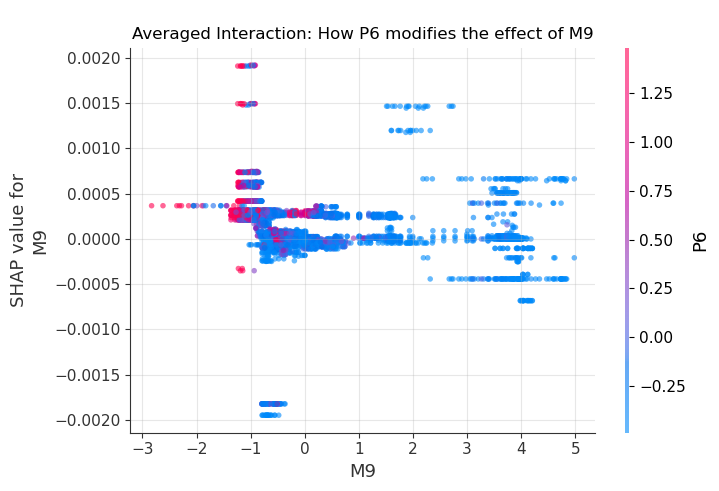

In [23]:
plot_shap_interaction(results, target_feature='M9', interaction_feature='P6', last_n_outer=7)

当 M9 为负且 P6 为正时，M9 的 SHAP 值偏正，说明 M9 在这些情形下对预测有向上的贡献；  
当 M9 为负且 P6 为负时，M9 的 SHAP 值偏负，说明 M9 在这些情形下对预测有向下的贡献  
可以构建`feature_df['M9_x_P6_Inverted'] = -1 * feature_df['M9'] * feature_df['P6']`

右侧当 M9 变正时，P6 变负了，但是具体预测向上和向下不明显，并且目前还没有想好构建什么合适的因子

Shape of all_shap: (4410, 100)
Shape of all_X_val: (4410, 100)


<Figure size 1000x600 with 0 Axes>

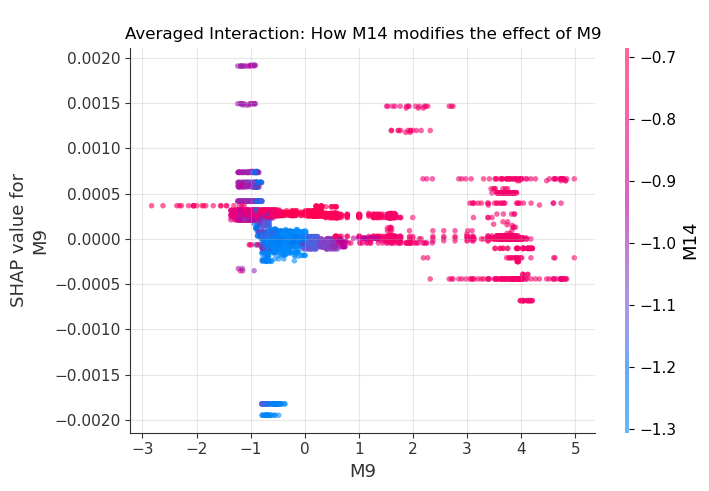

In [24]:
plot_shap_interaction(results, target_feature='M9', interaction_feature='M14', last_n_outer=7)